<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 1. Aspectos generales

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Explotación analítica en **Spark SQL** (usando CTEs, ventanas y agregaciones sobre vistas temporales de la capa **Gold**)
para responder a los indicadores estratégicos de los dashboards del Examen Final y auditar la ejecución completa
registrada en `audit/audit_pipeline.parquet`.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [2]:
# Inicializar SparkSession
spark = (
    SparkSession.builder
    .appName("MEF_SparkSQL_Analitica_Auditoria")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.sql.shuffle.partitions", "50")
    .config("spark.memory.fraction", "0.8")
    .getOrCreate()
)

spark.sparkContext.setCheckpointDir("/tmp/spark_checkpoint")
spark.sparkContext.setLogLevel("WARN")
spark

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 2. Registro de vistas temporales del Galaxy Schema

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Lee todas las tablas Parquet de `gold/` y `audit/audit_pipeline.parquet` y las registra como vistas temporales
mediante `createOrReplaceTempView` para consultas directas en Spark SQL.

In [3]:
%%time
GOLD  = "/home/jovyan/Final/proyecto_final/gold"
AUDIT = "/home/jovyan/Final/proyecto_final/audit/audit_pipeline.parquet"

vistas = [
    "dim_tiempo",
    "dim_entidad_municipalidad",
    "dim_geografia_ubigeo",
    "dim_clasificador_ingreso",
    "dim_fuente_rubro",
    "dim_tipo_recurso",
    "dim_formulario_pregunta",
    "fact_ejecucion_ingresos",
    "fact_metas_estadistica_atm",
    "fact_cuestionario_atm",
]
for v in vistas:
    spark.read.parquet(f"{GOLD}/{v}").createOrReplaceTempView(v)

spark.read.parquet(AUDIT).createOrReplaceTempView("audit_pipeline")
print(f"Vistas registradas en Spark SQL: {len(vistas) + 1}")

Vistas registradas en Spark SQL: 11
CPU times: user 23.6 ms, sys: 22.2 ms, total: 45.8 ms
Wall time: 11.2 s


<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 3. Indicador 1: Evolucion presupuestal y brecha PIM vs. Recaudado (SIAF)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula con CTEs y ventana `LAG` la serie histórica 2009–2026 para Gobiernos Locales (`NIVEL_GOBIERNO = 'M'`):
PIA, PIM, Recaudado neto, Brecha PIM vs. PIA (%), % de Ejecución s/PIM, Extornos negativos y Variación interanual.

In [4]:
%%time
df_evol_siaf = spark.sql("""
WITH base_muni AS (
    SELECT
        t.Anio,
        SUM(f.MONTO_PIA) / 1e6 AS pia_mill,
        SUM(f.MONTO_PIM) / 1e6 AS pim_mill,
        SUM(f.MONTO_RECAUDADO) / 1e6 AS recaudado_mill,
        SUM(CASE WHEN f.ES_EXTORNO_NEGATIVO THEN f.MONTO_RECAUDADO ELSE 0 END) / 1e6 AS extornos_mill
    FROM fact_ejecucion_ingresos f
    INNER JOIN dim_tiempo t ON f.SK_Fecha = t.SK_Fecha
    INNER JOIN dim_entidad_municipalidad e ON f.SK_Municipalidad = e.SK_Municipalidad
    WHERE e.NIVEL_GOBIERNO = 'M'
    GROUP BY t.Anio
)
SELECT
    Anio,
    ROUND(pia_mill, 1) AS PIA_M,
    ROUND(pim_mill, 1) AS PIM_M,
    ROUND(recaudado_mill, 1) AS Recaudado_M,
    ROUND((pim_mill - pia_mill) * 100.0 / NULLIF(pia_mill, 0), 1) AS Brecha_PIM_PIA_Pct,
    ROUND(recaudado_mill * 100.0 / NULLIF(pim_mill, 0), 1) AS Ejecucion_PIM_Pct,
    ROUND(extornos_mill, 1) AS Extornos_Neg_M,
    ROUND((recaudado_mill - LAG(recaudado_mill) OVER (ORDER BY Anio)) * 100.0 /
          NULLIF(LAG(recaudado_mill) OVER (ORDER BY Anio), 0), 1) AS Var_YoY_Pct
FROM base_muni
ORDER BY Anio
""")
df_evol_siaf.show(20, truncate=False)

+----+-------+-------+-----------+------------------+-----------------+--------------+-----------+
|Anio|PIA_M  |PIM_M  |Recaudado_M|Brecha_PIM_PIA_Pct|Ejecucion_PIM_Pct|Extornos_Neg_M|Var_YoY_Pct|
+----+-------+-------+-----------+------------------+-----------------+--------------+-----------+
|2009|11999.8|20695.9|18496.6    |72.5              |89.4             |-98.7         |null       |
|2010|9138.8 |20936.5|20161.7    |129.1             |96.3             |-109.6        |9.0        |
|2011|10793.5|21314.0|20858.4    |97.5              |97.9             |-155.0        |3.5        |
|2012|14826.2|27217.4|26288.4    |83.6              |96.6             |-238.2        |26.0       |
|2013|17559.5|28965.6|26579.9    |65.0              |91.8             |-280.4        |1.1        |
|2014|16353.0|27088.6|25872.6    |65.6              |95.5             |-316.2        |-2.7       |
|2015|15230.7|24004.5|23399.8    |57.6              |97.5             |-221.7        |-9.6       |
|2016|1426

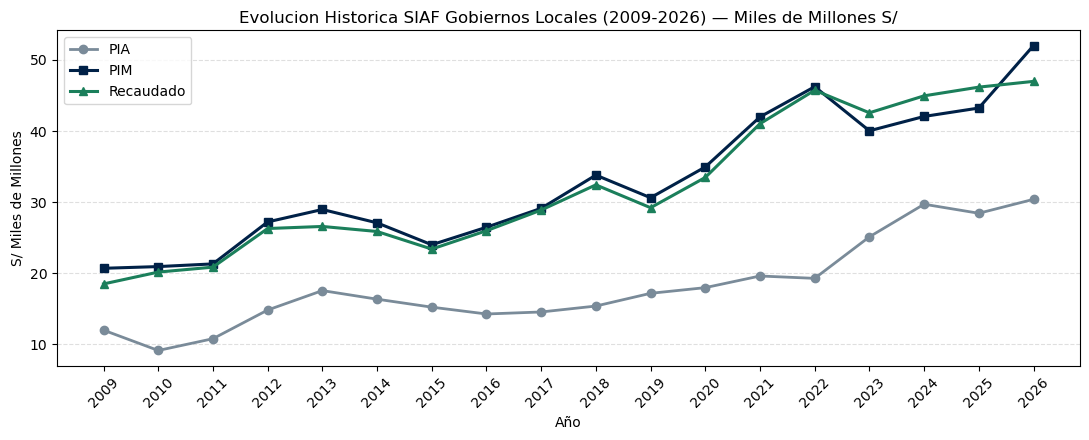

In [5]:
evol_pd = df_evol_siaf.toPandas()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(evol_pd["Anio"], evol_pd["PIA_M"] / 1000.0, marker="o", label="PIA", color="#7A8B99", linewidth=2)
ax.plot(evol_pd["Anio"], evol_pd["PIM_M"] / 1000.0, marker="s", label="PIM", color="#002147", linewidth=2.2)
ax.plot(evol_pd["Anio"], evol_pd["Recaudado_M"] / 1000.0, marker="^", label="Recaudado", color="#1B7F5B", linewidth=2.2)
ax.set_title("Evolucion Historica SIAF Gobiernos Locales (2009-2026) — Miles de Millones S/")
ax.set_xlabel("Año")
ax.set_ylabel("S/ Miles de Millones")
ax.set_xticks(evol_pd["Anio"])
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 4. Indicador 2: Efectividad Predial y cobranza coactiva por tramo A-G (SISMEPRE)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Evalúa sobre `fact_metas_estadistica_atm` (`Mes_Numero = 13`, años `2016–2025`, excluyendo atípicos `Ind_Outlier_Emision = 0`
e `Ind_Outlier_Saldo = 0`) la efectividad ponderada, el peso de la cobranza coactiva, los saldos morosos y el cumplimiento de meta
agrupados por `Clasificacion_ATM` (tramos A–G).

In [6]:
%%time
df_tramos_atm = spark.sql("""
WITH cierres_validos AS (
    SELECT
        COALESCE(e.Clasificacion_ATM, 'Sin Tramo') AS Tramo_ATM,
        m.SEC_EJEC,
        m.ANO_ESTADISTICA,
        CASE WHEN m.Ind_Outlier_Emision = 0 THEN m.Monto_Emision_Predial ELSE 0 END AS Emi,
        m.Monto_Recaudado_Ord AS Rec_Ord,
        m.Monto_Recaudado_Coact AS Rec_Coact,
        (m.Monto_Recaudado_Ord + m.Monto_Recaudado_Coact) AS Rec_Corr,
        CASE WHEN m.Ind_Outlier_Saldo = 0 THEN (m.Monto_Saldo_Ord + m.Monto_Saldo_Coact) ELSE 0 END AS Saldo_Real,
        m.Ind_Cumplimiento_Meta
    FROM fact_metas_estadistica_atm m
    INNER JOIN dim_tiempo t ON m.SK_Fecha = t.SK_Fecha
    INNER JOIN dim_entidad_municipalidad e ON m.SK_Municipalidad = e.SK_Municipalidad
    WHERE t.Mes_Numero = 13
      AND t.Anio BETWEEN 2016 AND 2025
)
SELECT
    Tramo_ATM,
    COUNT(DISTINCT SEC_EJEC) AS Munis,
    ROUND(SUM(Emi) / 1e6, 1) AS Emision_M,
    ROUND(SUM(Rec_Ord) / 1e6, 1) AS Rec_Ord_M,
    ROUND(SUM(Rec_Coact) / 1e6, 1) AS Rec_Coact_M,
    ROUND(SUM(CASE WHEN Emi > 0 AND Rec_Corr > 0 THEN Rec_Corr ELSE 0 END) * 100.0 /
          NULLIF(SUM(CASE WHEN Emi > 0 AND Rec_Corr > 0 THEN Emi ELSE 0 END), 0), 1) AS Efectividad_Pct,
    ROUND(SUM(Rec_Coact) * 100.0 / NULLIF(SUM(Rec_Corr), 0), 1) AS Peso_Coactivo_Pct,
    ROUND(SUM(Saldo_Real) / 1e6, 1) AS Saldo_Moroso_M,
    ROUND(AVG(CAST(Ind_Cumplimiento_Meta AS DOUBLE)) * 100.0, 1) AS Cumplimiento_Meta_Pct
FROM cierres_validos
GROUP BY Tramo_ATM
ORDER BY Tramo_ATM
""")
df_tramos_atm.show(truncate=False)

+---------+-----+---------+---------+-----------+---------------+-----------------+--------------+---------------------+
|Tramo_ATM|Munis|Emision_M|Rec_Ord_M|Rec_Coact_M|Efectividad_Pct|Peso_Coactivo_Pct|Saldo_Moroso_M|Cumplimiento_Meta_Pct|
+---------+-----+---------+---------+-----------+---------------+-----------------+--------------+---------------------+
|A        |74   |7511.9   |3993.4   |192.1      |56.3           |4.6              |6447.5        |74.6                 |
|B        |121  |335.6    |160.3    |1.9        |48.0           |1.2              |376.4         |67.8                 |
|C        |42   |11662.6  |8294.0   |516.0      |76.0           |5.9              |8080.5        |79.8                 |
|D        |129  |4632.8   |2128.6   |40.5       |49.0           |1.9              |5305.7        |70.2                 |
|E        |345  |1552.4   |882.4    |69.1       |43.3           |7.3              |1864.2        |59.1                 |
|F        |181  |126.8    |48.1 

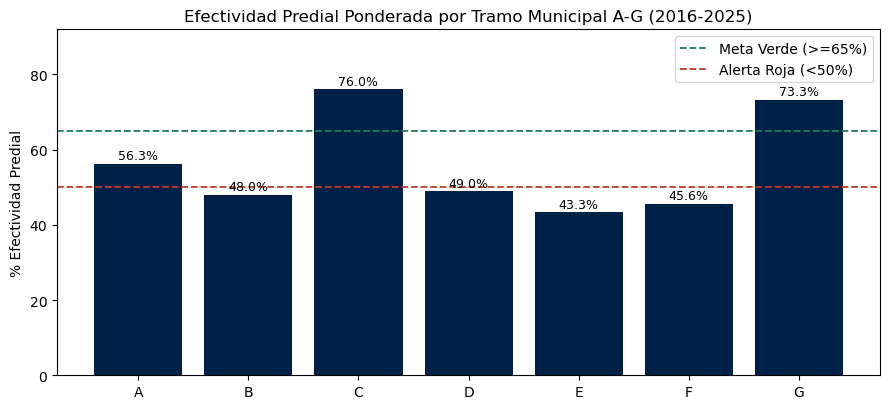

In [7]:
tramos_pd = df_tramos_atm.filter(F.col("Tramo_ATM").isin(["A", "B", "C", "D", "E", "F", "G"])).toPandas()
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(tramos_pd["Tramo_ATM"], tramos_pd["Efectividad_Pct"], color="#002147")
ax.axhline(65.0, color="#1B7F5B", linestyle="--", linewidth=1.3, label="Meta Verde (>=65%)")
ax.axhline(50.0, color="#C0392B", linestyle="--", linewidth=1.3, label="Alerta Roja (<50%)")
for b in bars:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width() / 2, h + 1.2, f"{h:.1f}%", ha="center", fontsize=9)
ax.set_ylim(0, 92)
ax.set_title("Efectividad Predial Ponderada por Tramo Municipal A-G (2016-2025)")
ax.set_ylabel("% Efectividad Predial")
ax.legend()
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 5. Indicador 3: Brecha digital y dotacion RRHH (Cruce SIAF x RENAMU 2022)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Cruza `fact_ejecucion_ingresos` (recaudación predial vía `dim_clasificador_ingreso.ES_PREDIAL`) con los atributos censales
de `dim_entidad_municipalidad` (`Software_Tributario`, `Catastro_Urbano`, `P32_1_T_Personal_Trib`, `Indice_TIC_Rentas`).

In [8]:
%%time
df_tic = spark.sql("""
WITH predial_muni AS (
    SELECT
        e.SEC_EJEC,
        e.Software_Tributario,
        e.Catastro_Urbano,
        e.P32_1_T_Personal_Trib,
        e.Indice_TIC_Rentas,
        SUM(f.MONTO_RECAUDADO) AS Rec_Predial_Total
    FROM fact_ejecucion_ingresos f
    INNER JOIN dim_clasificador_ingreso c ON f.SK_Clasificador = c.SK_Clasificador
    INNER JOIN dim_entidad_municipalidad e ON f.SK_Municipalidad = e.SK_Municipalidad
    WHERE e.NIVEL_GOBIERNO = 'M'
      AND c.ES_PREDIAL = TRUE
    GROUP BY e.SEC_EJEC, e.Software_Tributario, e.Catastro_Urbano, e.P32_1_T_Personal_Trib, e.Indice_TIC_Rentas
)
SELECT
    CASE WHEN Software_Tributario = 1 THEN 'Con Software Tributario (P17_7=1)' ELSE 'Registro Manual / Sin SW (P17_7=0)' END AS Grupo_TIC,
    CASE WHEN Catastro_Urbano = 1 THEN 'Con Catastro (P17_8=1)' ELSE 'Sin Catastro (P17_8=0)' END AS Grupo_Catastro,
    COUNT(*) AS Munis,
    ROUND(AVG(P32_1_T_Personal_Trib), 1) AS Prom_Personal_ATM,
    ROUND(AVG(Rec_Predial_Total) / 1e6, 2) AS Prom_Rec_Predial_M,
    ROUND(SUM(Rec_Predial_Total) / NULLIF(SUM(P32_1_T_Personal_Trib), 0) / 1e3, 1) AS Rec_Predial_Miles_x_Trabajador
FROM predial_muni
GROUP BY 1, 2
ORDER BY Prom_Rec_Predial_M DESC
""")
df_tic.show(truncate=False)

+----------------------------------+----------------------+-----+-----------------+------------------+------------------------------+
|Grupo_TIC                         |Grupo_Catastro        |Munis|Prom_Personal_ATM|Prom_Rec_Predial_M|Rec_Predial_Miles_x_Trabajador|
+----------------------------------+----------------------+-----+-----------------+------------------+------------------------------+
|Con Software Tributario (P17_7=1) |Con Catastro (P17_8=1)|218  |15.3             |67.8              |4441.4                        |
|Con Software Tributario (P17_7=1) |Sin Catastro (P17_8=0)|624  |7.6              |21.94             |2897.2                        |
|Registro Manual / Sin SW (P17_7=0)|Con Catastro (P17_8=1)|35   |2.5              |7.19              |2828.9                        |
|Registro Manual / Sin SW (P17_7=0)|Sin Catastro (P17_8=0)|931  |1.7              |3.6               |2084.2                        |
+----------------------------------+----------------------+---

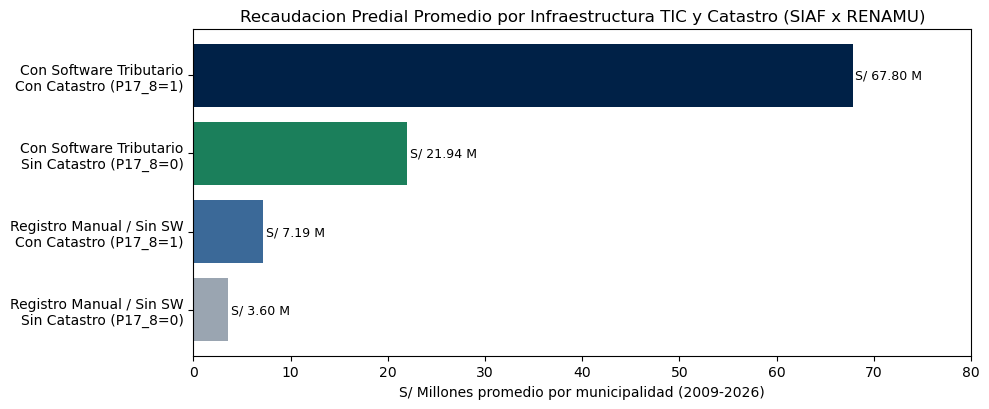

In [9]:
tic_pd = df_tic.toPandas()
tic_pd["Etiqueta"] = tic_pd["Grupo_TIC"].str.replace(" (P17_7=1)", "", regex=False).str.replace(" (P17_7=0)", "", regex=False) + "\n" + tic_pd["Grupo_Catastro"]
fig, ax = plt.subplots(figsize=(10, 4.2))
bars = ax.barh(tic_pd["Etiqueta"][::-1], tic_pd["Prom_Rec_Predial_M"][::-1], color=["#9AA5B1", "#3B6998", "#1B7F5B", "#002147"])
for b in bars:
    w = b.get_width()
    ax.text(w + 0.3, b.get_y() + b.get_height() / 2, f"S/ {w:.2f} M", va="center", fontsize=9)
ax.set_xlim(0, tic_pd["Prom_Rec_Predial_M"].max() * 1.18)
ax.set_title("Recaudacion Predial Promedio por Infraestructura TIC y Catastro (SIAF x RENAMU)")
ax.set_xlabel("S/ Millones promedio por municipalidad (2009-2026)")
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 6. Indicador 4: Autonomia fiscal territorial y madurez institucional ATM

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Calcula el **Índice de Autonomía Fiscal** (`Rubros 08 + 09` sobre el total recaudado frente a transferencias `07 + 18`)
por Región Natural, Departamento y Tipología Municipal (`Provincial` vs. `Distrital`), así como el índice `Puntaje_Madurez_ATM`
desde `fact_cuestionario_atm`.

In [10]:
%%time
df_autonomia_reg = spark.sql("""
SELECT
    g.Region_Natural,
    e.Tipo_Municipalidad,
    ROUND(SUM(CASE WHEN r.RUBRO IN ('08', '09') THEN f.MONTO_RECAUDADO ELSE 0 END) / 1e6, 1) AS Ingresos_Propios_M,
    ROUND(SUM(CASE WHEN r.RUBRO IN ('07', '18') THEN f.MONTO_RECAUDADO ELSE 0 END) / 1e6, 1) AS Transferencias_M,
    ROUND(SUM(f.MONTO_RECAUDADO) / 1e6, 1) AS Total_Recaudado_M,
    ROUND(SUM(CASE WHEN r.RUBRO IN ('08', '09') THEN f.MONTO_RECAUDADO ELSE 0 END) * 100.0 /
          NULLIF(SUM(f.MONTO_RECAUDADO), 0), 1) AS Indice_Autonomia_Pct
FROM fact_ejecucion_ingresos f
INNER JOIN dim_entidad_municipalidad e ON f.SK_Municipalidad = e.SK_Municipalidad
INNER JOIN dim_geografia_ubigeo g ON f.SK_Ubigeo = g.SK_Ubigeo
INNER JOIN dim_fuente_rubro r ON f.SK_Fuente_Rubro = r.SK_Fuente_Rubro
WHERE e.NIVEL_GOBIERNO = 'M'
GROUP BY g.Region_Natural, e.Tipo_Municipalidad
ORDER BY Indice_Autonomia_Pct DESC
""")
df_autonomia_reg.show(truncate=False)

print("--- Top 10 Departamentos por Indice de Autonomia Fiscal (Gobiernos Locales) ---")
spark.sql("""
SELECT
    g.Departamento,
    ROUND(SUM(CASE WHEN r.RUBRO IN ('08', '09') THEN f.MONTO_RECAUDADO ELSE 0 END) / 1e6, 1) AS Propios_M,
    ROUND(SUM(CASE WHEN r.RUBRO IN ('07', '18') THEN f.MONTO_RECAUDADO ELSE 0 END) / 1e6, 1) AS Transferencias_M,
    ROUND(SUM(CASE WHEN r.RUBRO IN ('08', '09') THEN f.MONTO_RECAUDADO ELSE 0 END) * 100.0 /
          NULLIF(SUM(f.MONTO_RECAUDADO), 0), 1) AS Autonomia_Pct
FROM fact_ejecucion_ingresos f
INNER JOIN dim_entidad_municipalidad e ON f.SK_Municipalidad = e.SK_Municipalidad
INNER JOIN dim_geografia_ubigeo g ON f.SK_Ubigeo = g.SK_Ubigeo
INNER JOIN dim_fuente_rubro r ON f.SK_Fuente_Rubro = r.SK_Fuente_Rubro
WHERE e.NIVEL_GOBIERNO = 'M' AND g.SK_Ubigeo <> '000000'
GROUP BY g.Departamento
ORDER BY Autonomia_Pct DESC
""").show(10, truncate=False)

print("--- Madurez Institucional ATM por Tramo (fact_cuestionario_atm) ---")
spark.sql("""
WITH entidad_campana AS (
    SELECT DISTINCT
        c.SEC_EJEC,
        c.ANO_APLICACION,
        c.PERIODO,
        COALESCE(e.Clasificacion_ATM, 'Sin Tramo') AS Tramo_ATM,
        c.Puntaje_Madurez_ATM,
        c.Tiene_Coactivo_Activo,
        c.Tiene_Sistema_Rentas
    FROM fact_cuestionario_atm c
    INNER JOIN dim_entidad_municipalidad e ON c.SK_Municipalidad = e.SK_Municipalidad
)
SELECT
    Tramo_ATM,
    COUNT(DISTINCT SEC_EJEC) AS Munis_Encuestadas,
    ROUND(AVG(Puntaje_Madurez_ATM), 1) AS Madurez_ATM_Prom,
    ROUND(AVG(CAST(Tiene_Coactivo_Activo AS DOUBLE)) * 100.0, 1) AS Pct_Con_Coactivo,
    ROUND(AVG(CAST(Tiene_Sistema_Rentas AS DOUBLE)) * 100.0, 1) AS Pct_Con_Sistema
FROM entidad_campana
GROUP BY Tramo_ATM
ORDER BY Tramo_ATM
""").show(truncate=False)

+--------------+------------------+------------------+----------------+-----------------+--------------------+
|Region_Natural|Tipo_Municipalidad|Ingresos_Propios_M|Transferencias_M|Total_Recaudado_M|Indice_Autonomia_Pct|
+--------------+------------------+------------------+----------------+-----------------+--------------------+
|Costa         |Provincial        |46207.2           |45681.6         |120938.8         |38.2                |
|Costa         |Distrital         |62155.6           |103152.3        |185781.7         |33.5                |
|Sierra        |Provincial        |11411.7           |52487.8         |75423.2          |15.1                |
|Selva         |Provincial        |2508.6            |12083.0         |17912.6          |14.0                |
|Selva         |Distrital         |1518.6            |15491.2         |20977.2          |7.2                 |
|Sierra        |Distrital         |9662.5            |124534.5        |158023.8         |6.1                 |
|

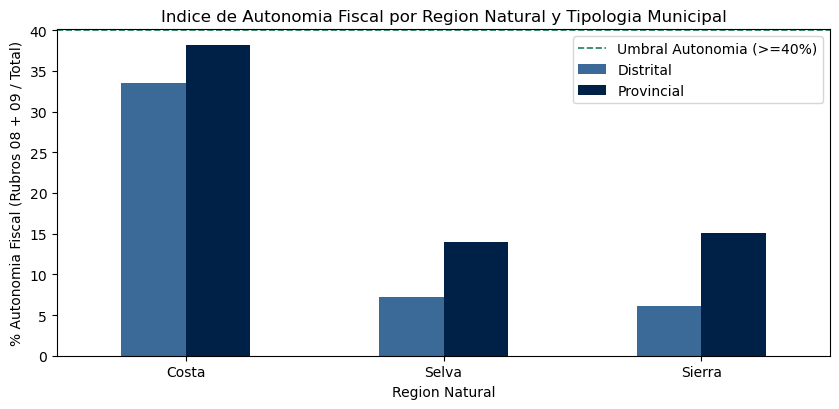

In [11]:
auto_pd = df_autonomia_reg.filter(F.col("Region_Natural") != "Sin Dato").toPandas()
auto_pd["Indice_Autonomia_Pct"] = auto_pd["Indice_Autonomia_Pct"].astype(float)
piv = auto_pd.pivot(index="Region_Natural", columns="Tipo_Municipalidad", values="Indice_Autonomia_Pct").fillna(0).astype(float)
ax = piv.plot(kind="bar", figsize=(8.5, 4.2), color=["#3B6998", "#002147"])
ax.axhline(40.0, color="#1B7F5B", linestyle="--", linewidth=1.2, label="Umbral Autonomia (>=40%)")
ax.set_title("Indice de Autonomia Fiscal por Region Natural y Tipologia Municipal")
ax.set_ylabel("% Autonomia Fiscal (Rubros 08 + 09 / Total)")
ax.set_xlabel("Region Natural")
ax.tick_params(axis="x", rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

<div style="background-color:#002147; color:white; padding:10px; border-radius:5px; font-size:18px"> 7. Auditoria integral del Pipeline Medallon (audit_pipeline.parquet)

<div style="background-color:#9B9B9B; color:white; padding:10px; border-radius:5px; font-size:13px">

Consulta sobre `/home/jovyan/Final/proyecto_final/audit/audit_pipeline.parquet` mostrando el resumen por capa
y los **32 registros completos** de auditoría del pipeline (`BRONZE`, `SILVER`, `GOLD` y `GOLD_MARTS`).

In [12]:
print("--- Resumen de ejecucion por Capa Medallon ---")
spark.sql("""
SELECT
    capa,
    COUNT(*) AS procesos,
    ROUND(SUM(duracion_seg), 2) AS duracion_total_seg,
    SUM(filas_leidas) AS total_leidas,
    SUM(filas_escritas) AS total_escritas,
    SUM(filas_descartadas) AS total_descartadas,
    MIN(estado) AS estado_global
FROM audit_pipeline
GROUP BY capa
ORDER BY MIN(fecha_inicio)
""").show(truncate=False)

print("--- Detalle completo de los 32 registros en audit_pipeline.parquet ---")
spark.sql("""
SELECT
    capa,
    proceso_script,
    fuente_tabla,
    DATE_FORMAT(fecha_inicio, 'yyyy-MM-dd HH:mm:ss') AS inicio,
    duracion_seg,
    filas_leidas,
    filas_escritas,
    filas_descartadas,
    estado
FROM audit_pipeline
ORDER BY fecha_inicio
""").show(40, truncate=False)

--- Resumen de ejecucion por Capa Medallon ---
+----------+--------+------------------+------------+--------------+-----------------+-------------+
|capa      |procesos|duracion_total_seg|total_leidas|total_escritas|total_descartadas|estado_global|
+----------+--------+------------------+------------+--------------+-----------------+-------------+
|BRONZE    |9       |224.37            |17214985    |17214985      |0                |EXITOSO      |
|SILVER    |9       |394.33            |17214985    |13193745      |4022429          |EXITOSO      |
|GOLD      |10      |145.19            |13182156    |10785492      |2396664          |EXITOSO      |
|GOLD_MARTS|4       |32.04             |21136464    |44207         |21092257         |EXITOSO      |
+----------+--------+------------------+------------+--------------+-----------------+-------------+

--- Detalle completo de los 32 registros en audit_pipeline.parquet ---
+----------+------------------------+------------------------------------

In [13]:
spark.stop()